# Evaluation

In [1]:
import json
from dataclasses import fields
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

from schemas import CLASSES, History, best_epoch
from summary import fold_number

RUN_DIR = Path("sessions/2026-11-10_002227")

config = json.loads((RUN_DIR / "args.json").read_text())
selection = config.get("selection", "loss")
histories = {
    fold_number(p): pd.read_csv(p)
    for p in sorted(RUN_DIR.glob("history_fold_*.csv"), key=fold_number)
}
val = pd.read_csv(RUN_DIR / "val_summary.csv", index_col=0)
if not (RUN_DIR / "test_results.csv").exists():
    raise SystemExit(f"Run first: python evaluate.py {RUN_DIR}")
test = pd.read_csv(RUN_DIR / "test_results.csv", index_col=0)
predictions = pd.read_csv(RUN_DIR / "test_predictions.csv")
y_true = predictions["Class"].map(CLASSES.index).to_numpy()
y_pred = predictions["Predicted"].map(CLASSES.index).to_numpy()
probs = predictions[[f"P({c})" for c in CLASSES]].to_numpy()
pd.Series(config)

backbone              resnet18
csv_dir               data/csv
epochs                      30
batch_size                  32
lr                      0.0001
weight_decay              0.01
slices_per_subject          32
warmup_epochs                1
patience                    10
seed                        42
num_workers                  8
augment                   True
amp                       True
dtype: object

## Training curves

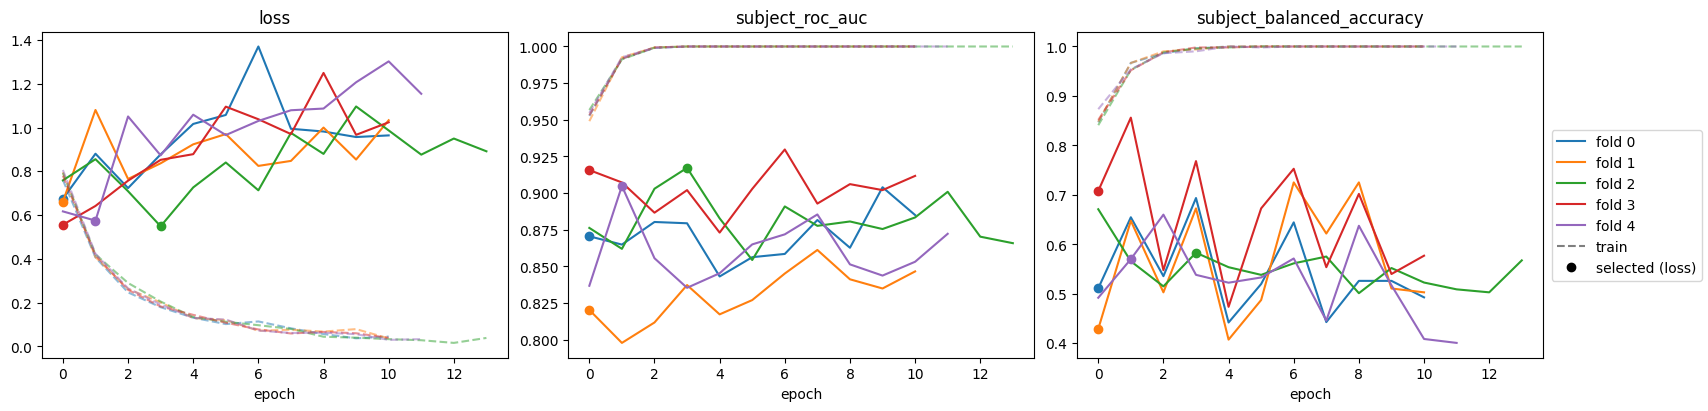

In [2]:
curves = ["loss", "subject_roc_auc", "subject_balanced_accuracy"]
fig, axes = plt.subplots(
    1, len(curves), figsize=(5 * len(curves) + 2, 4), sharex=True, layout="constrained"
)
for fold, history in histories.items():
    color = f"C{fold}"
    val_history = History(
        **{f.name: history[f"val_{f.name}"].tolist() for f in fields(History)}
    )
    epoch = best_epoch(val_history, selection)
    for axis, metric in zip(axes, curves):
        axis.plot(
            history["epoch"],
            history[f"train_{metric}"],
            color=color,
            ls="--",
            alpha=0.5,
        )
        axis.plot(
            history["epoch"],
            history[f"val_{metric}"],
            color=color,
            label=f"fold {fold}",
        )
        axis.plot(epoch, history.at[epoch, f"val_{metric}"], "o", color=color)
for axis, metric in zip(axes, curves):
    axis.set(title=metric, xlabel="epoch")
axes[0].plot([], [], "k--", alpha=0.5, label="train")
axes[0].plot([], [], "ko", label=f"selected ({selection})")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right center")

## Validation vs test

subject_roc_auc  subject_average_precision  \
val  mean               0.8857                     0.6280   
     std                0.0411                     0.0649   
test fold_0             0.8235                     0.5585   
     fold_1             0.8482                     0.5651   
     fold_2             0.8344                     0.5354   
     fold_3             0.8421                     0.5817   
     fold_4             0.8334                     0.5323   
     mean               0.8363                     0.5546   
     std                0.0093                     0.0208   
     ensemble           0.8506                     0.5895   

               subject_balanced_accuracy  roc_auc  balanced_accuracy  
val  mean                         0.5603   0.8436             0.5428  
     std                          0.1026   0.0424             0.0921  
test fold_0                       0.4738   0.7843             0.4946  
     fold_1                       0.4471   0.8027             0.4601  
     fold_2                       0.5052   0.8192             0.4812  
     fold_3                       0.6127   0.8052             0.5810  
     fold_4                       0.4838   0.7987             0.4759  
     mean                         0.5045   0.8020             0.4986  
     std                          0.0640   0.0126             0.0477  
     ensemble                     0.5115   0.8227             0.5133

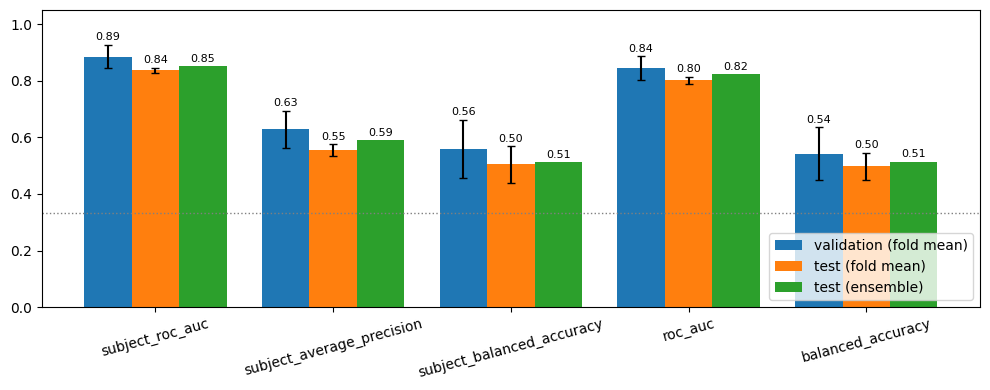

In [3]:
metrics = [
    "subject_roc_auc",
    "subject_average_precision",
    "subject_balanced_accuracy",
    "roc_auc",
    "balanced_accuracy",
]
groups = {
    "validation (fold mean)": (val.loc["mean", metrics], val.loc["std", metrics]),
    "test (fold mean)": (test.loc["mean", metrics], test.loc["std", metrics]),
    "test (ensemble)": (test.loc["ensemble", metrics], None),
}
x = np.arange(len(metrics))
width = 0.8 / len(groups)
fig, axis = plt.subplots(figsize=(10, 4))
for i, (name, (mean, std)) in enumerate(groups.items()):
    bars = axis.bar(x + (i - 1) * width, mean, width, yerr=std, capsize=3, label=name)
    axis.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
axis.axhline(1 / len(CLASSES), color="gray", ls=":", lw=1)
axis.set_xticks(x, metrics, rotation=15)
axis.set_ylim(0, 1.05)
axis.legend(loc="lower right")
fig.tight_layout()
pd.concat({"val": val[metrics].loc[["mean", "std"]], "test": test[metrics]}).round(4)

## Confusion matrix (subjects, ensemble)

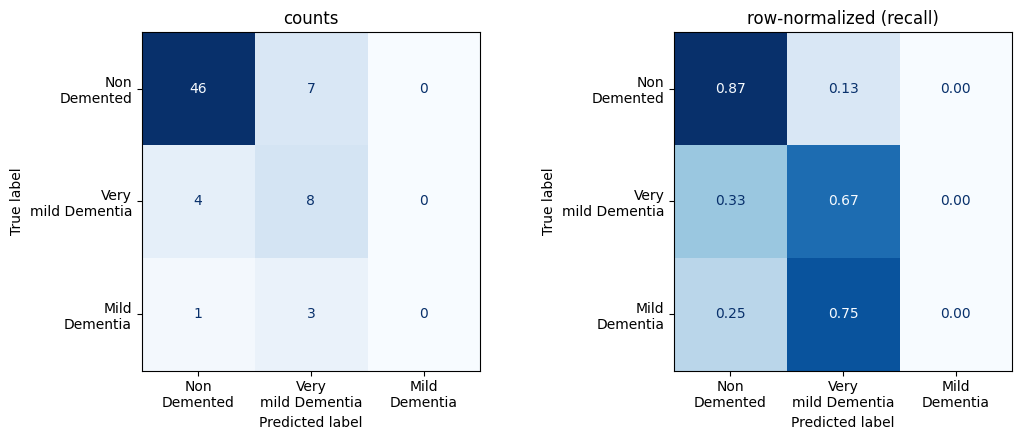

In [4]:
labels = [c.replace(" ", "\n", 1) for c in CLASSES]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, normalize in zip(axes, [None, "true"]):
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=range(len(CLASSES)),
        display_labels=labels,
        normalize=normalize,
        values_format=".2f" if normalize else "d",
        cmap="Blues",
        colorbar=False,
        ax=axis,
    )
axes[0].set_title("counts")
axes[1].set_title("row-normalized (recall)")
fig.tight_layout()

## ROC and precision-recall (subjects, ensemble, one-vs-rest)

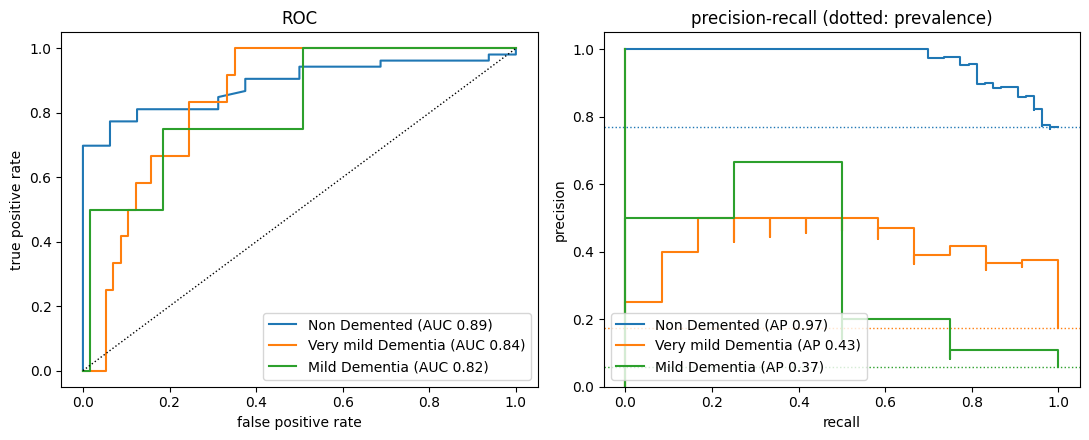

In [5]:
fig, (roc_axis, pr_axis) = plt.subplots(1, 2, figsize=(11, 4.5))
for k, name in enumerate(CLASSES):
    positive = y_true == k
    fpr, tpr, _ = roc_curve(positive, probs[:, k])
    roc_axis.plot(
        fpr, tpr, label=f"{name} (AUC {roc_auc_score(positive, probs[:, k]):.2f})"
    )
    precision, recall, _ = precision_recall_curve(positive, probs[:, k])
    pr_axis.step(
        recall,
        precision,
        where="post",
        color=f"C{k}",
        label=f"{name} (AP {average_precision_score(positive, probs[:, k]):.2f})",
    )
    pr_axis.axhline(positive.mean(), color=f"C{k}", ls=":", lw=1)
roc_axis.plot([0, 1], [0, 1], "k:", lw=1)
roc_axis.set(xlabel="false positive rate", ylabel="true positive rate", title="ROC")
pr_axis.set(
    xlabel="recall",
    ylabel="precision",
    title="precision-recall (dotted: prevalence)",
    ylim=(0, 1.05),
)
roc_axis.legend(loc="lower right")
pr_axis.legend(loc="lower left")
fig.tight_layout()